# Gộp bảng và tạo đặc trưng

Bảy bảng được gộp ở notebook này. Các hàm gộp dài đặt trong code/data.py để tái sử dụng, còn tham số và output nằm trong cell.

['studentInfo.csv', 'studentRegistration.csv', 'assessments.csv', 'studentAssessment.csv', 'studentVle.csv', 'vle.csv', 'courses.csv']


(32593, 35)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,clicks_late,clicks_forumng,clicks_homepage,clicks_oucontent,clicks_quiz,clicks_resource,clicks_subpage,clicks_url,module_presentation_length,risk
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,342.0,193.0,138.0,553.0,0.0,13.0,32.0,5.0,268,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,561.0,417.0,324.0,537.0,0.0,12.0,87.0,48.0,268,0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,0.0,126.0,59.0,66.0,0.0,4.0,22.0,4.0,268,1
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,1079.0,634.0,432.0,836.0,0.0,19.0,144.0,90.0,268,0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,312.0,194.0,204.0,494.0,0.0,45.0,79.0,14.0,268,0


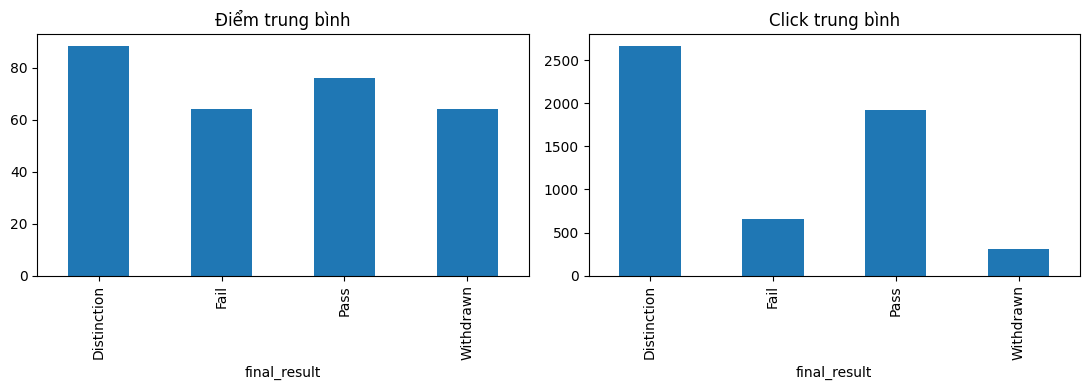

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists() and (ROOT.parent / 'clht_code').exists():
    ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
DATA=ROOT/'data'
OUT=ROOT/'ket_qua'
OUT.mkdir(exist_ok=True)
import pandas as pd
import matplotlib.pyplot as plt
from clht_code.data import merge_full_tables, source_manifest
print(list(source_manifest(DATA)))
full=merge_full_tables(DATA); print(full.shape)
assert full.duplicated(['id_student','code_module','code_presentation']).sum()==0
full.to_csv(OUT/'du_lieu_da_gop_tao_dac_trung.csv',index=False,encoding='utf-8-sig'); display(full.head())
fig,ax=plt.subplots(1,2,figsize=(11,4)); full.groupby('final_result').avg_score.mean().plot.bar(ax=ax[0],title='Điểm trung bình'); full.groupby('final_result').total_clicks.mean().plot.bar(ax=ax[1],title='Click trung bình'); fig.tight_layout(); fig.savefig(OUT/'dac_trung_theo_nhan.png',dpi=150); plt.show()